<h2>Лабораторна робота №3 «Exploratory Data Analysis and Feature Engineering»</h2>

In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_curve, RocCurveDisplay)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

<h3>1. Завантажити та підготувати дані для навчання</h3>

In [32]:
train_df = pd.read_csv('application_train.csv')
test_df = pd.read_csv('application_test.csv')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()

Train shape: (307511, 122)
Test shape: (48744, 121)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Аналіз розподілів числових та категоріальних ознак

count       307511.0
mean        168798.0
std         237123.0
min          25650.0
25%         112500.0
50%         147150.0
75%         202500.0
max      117000000.0
Name: AMT_INCOME_TOTAL, dtype: float64


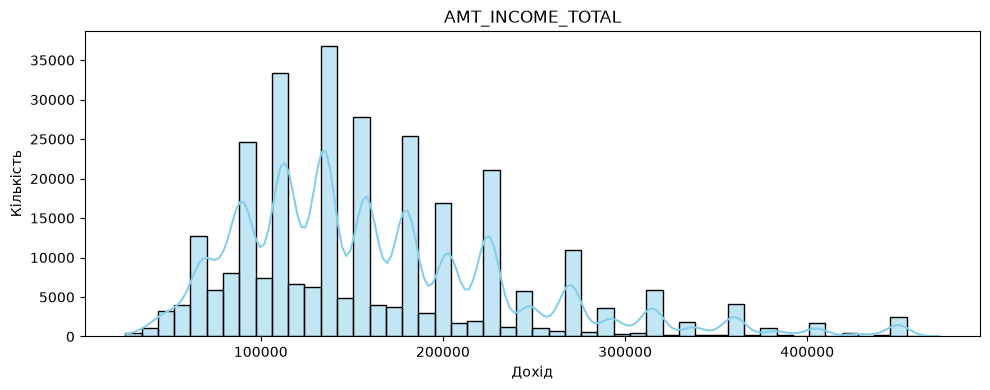

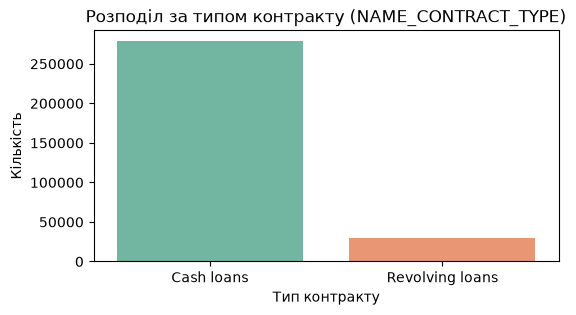

In [33]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = train_df.select_dtypes(include=['object', 'str']).columns.tolist()

income = train_df['AMT_INCOME_TOTAL']
print(income.describe().round(0))

fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(income[income <= income.quantile(0.99)], bins=50, kde=True, color='skyblue', ax=ax)
ax.set_title('AMT_INCOME_TOTAL')
ax.set_xlabel('Дохід')
ax.set_ylabel('Кількість')

plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 3))
sns.countplot(data=train_df, x='NAME_CONTRACT_TYPE', hue='NAME_CONTRACT_TYPE', palette='Set2', legend=False)
plt.title('Розподіл за типом контракту (NAME_CONTRACT_TYPE)')
plt.xlabel('Тип контракту')
plt.ylabel('Кількість')
plt.show()

аналіз пропущених значень;


In [34]:
missing_data = train_df.isnull().mean() * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

print(f"Загальна кількість колонок із пропусками: {len(missing_data)}")
print("\nТОП-10 колонок із найбільшою кількістю пропусків (%):")
print(missing_data.head(10))

Загальна кількість колонок із пропусками: 67

ТОП-10 колонок із найбільшою кількістю пропусків (%):
COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
dtype: float64


аналіз збалансованості класів;



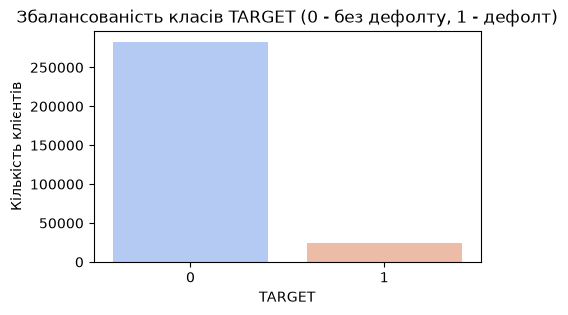

In [35]:
target_counts = train_df['TARGET'].value_counts()
target_percent = train_df['TARGET'].value_counts(normalize=True) * 100

plt.figure(figsize=(5, 3))
sns.countplot(data=train_df, x='TARGET', hue='TARGET', palette='coolwarm', legend=False)
plt.title('Збалансованість класів TARGET (0 - без дефолту, 1 - дефолт)')
plt.xlabel('TARGET')
plt.ylabel('Кількість клієнтів')
plt.show()

дослідження зв'язку окремих ознак із цільовою змінною;


ТОП-5 ознак з найбільшою позитивною кореляцією:
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64

ТОП-5 ознак з найбільшою негативною кореляцією (найбільш інформативні):
EXT_SOURCE_3    -0.178919
EXT_SOURCE_2    -0.160472
EXT_SOURCE_1    -0.155317
DAYS_EMPLOYED   -0.044932
FLOORSMAX_AVG   -0.044003
Name: TARGET, dtype: float64


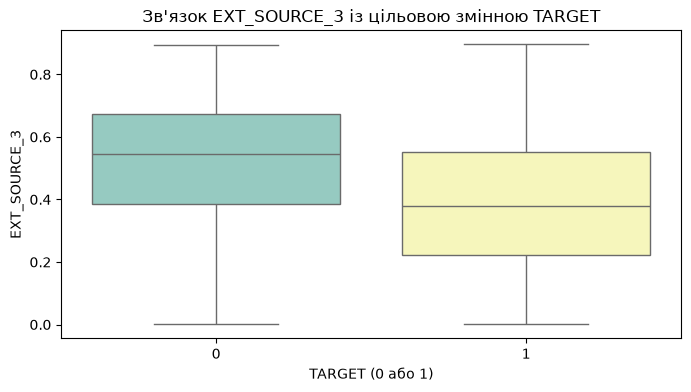

In [36]:
correlations = train_df[numeric_cols].corr()['TARGET'].sort_values()

print("ТОП-5 ознак з найбільшою позитивною кореляцією:")
print(correlations.tail(5))
print("\nТОП-5 ознак з найбільшою негативною кореляцією (найбільш інформативні):")
print(correlations.head(5))

plt.figure(figsize=(8, 4))
sns.boxplot(data=train_df, x='TARGET', y='EXT_SOURCE_3', hue='TARGET', palette='Set3', legend =False)
plt.title('Зв\'язок EXT_SOURCE_3 із цільовою змінною TARGET')
plt.xlabel('TARGET (0 або 1)')
plt.ylabel('EXT_SOURCE_3')
plt.show()

пошук потенційно корисних закономірностей для побудови моделі.


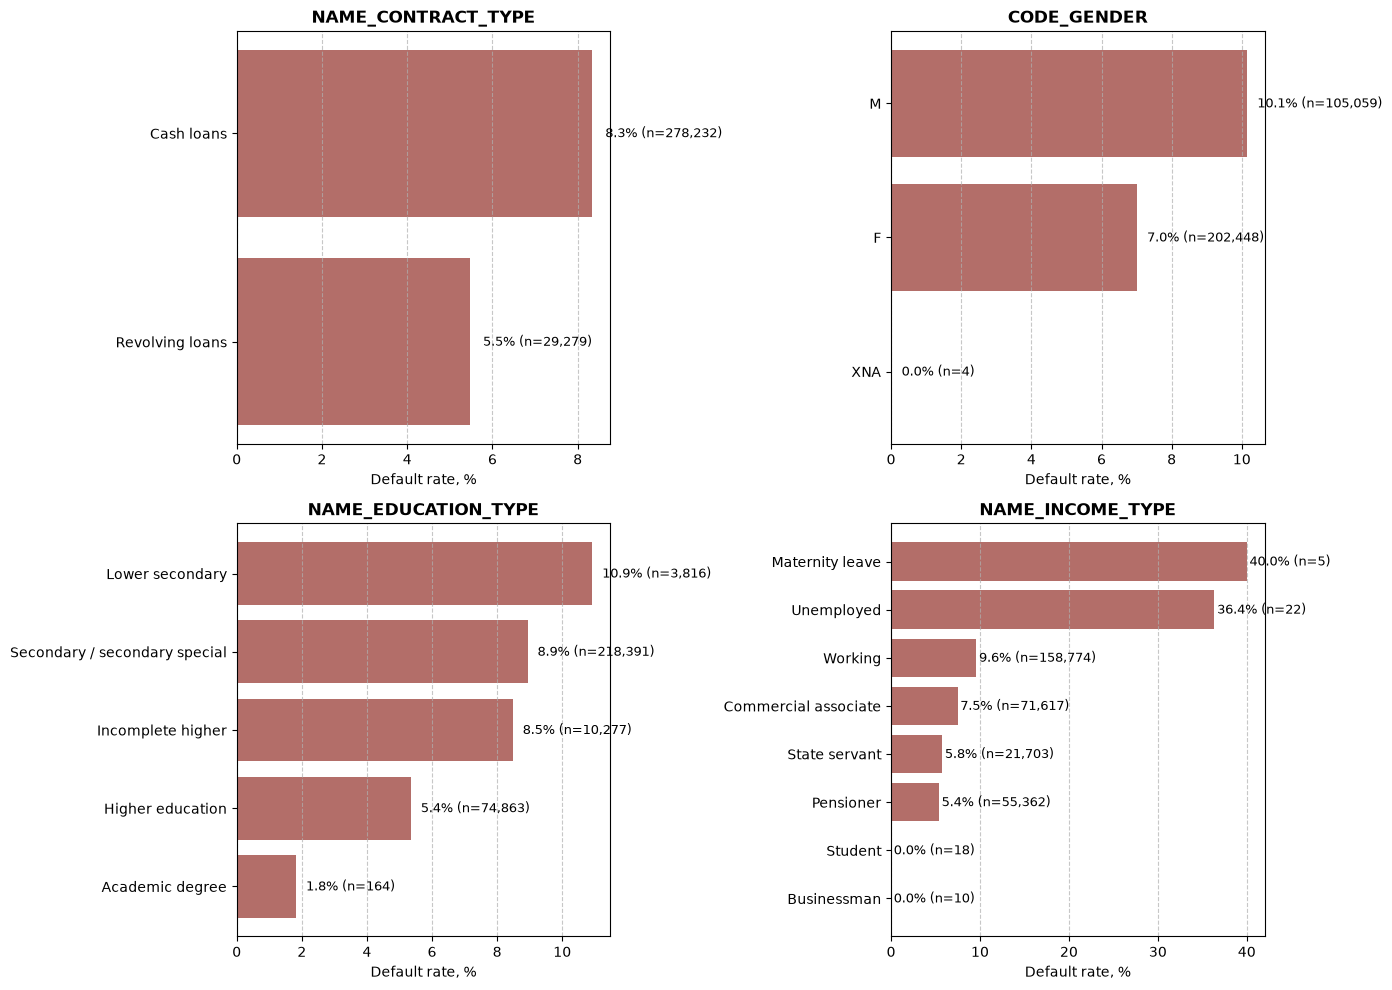

In [37]:
cat_cols = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten() 
for i, col in enumerate(cat_cols):
    ax = axes[i]
    
    stats = train_df.groupby(col, observed=True)['TARGET'].agg(
        rate=lambda x: x.mean() * 100,
        n='count'
    ).reset_index()
    
    stats = stats.sort_values('rate', ascending=True)
    
    bars = ax.barh(stats[col], stats['rate'], color='#a6554f', alpha=0.85)
    
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Default rate, %')
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    
    for bar, (_, row) in zip(bars, stats.iterrows()):
        width = bar.get_width()
        ax.text(
            width + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{row['rate']:.1f}% (n={row['n']:,})",
            va='center',
            ha='left',
            fontsize=9,
            color='black'
        )

plt.tight_layout()
plt.show()

In [49]:
def add_features(df):
    df_new = df.copy()

    df_new['DAYS_EMPLOYED_ANOM'] = (df_new['DAYS_EMPLOYED'] == 365243).astype(int)
    df_new['DAYS_EMPLOYED'] = df_new['DAYS_EMPLOYED'].replace(365243, np.nan)

    df_new['CREDIT_INCOME_RATIO'] = df_new['AMT_CREDIT'] / (df_new['AMT_INCOME_TOTAL'] + 1e-5)
    df_new['ANNUITY_INCOME_RATIO'] = df_new['AMT_ANNUITY'] / (df_new['AMT_INCOME_TOTAL'] + 1e-5)
    df_new['CREDIT_TERM'] = df_new['AMT_CREDIT'] / (df_new['AMT_ANNUITY'] + 1e-5)
    df_new['AGE_YEARS'] = df_new['DAYS_BIRTH'] / -365.25
    df_new['EMPLOYED_YEARS'] = df_new['DAYS_EMPLOYED'] / -365.25
    df_new['EMPLOYED_TO_AGE_RATIO'] = df_new['EMPLOYED_YEARS'] / df_new['AGE_YEARS']

    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df_new['EXT_SOURCE_MEAN'] = df_new[ext_cols].mean(axis=1)
    df_new['EXT_SOURCE_STD'] = df_new[ext_cols].std(axis=1).fillna(0)
    df_new['EXT_SOURCE_MISSING_CNT'] = df_new[ext_cols].isnull().sum(axis=1)

    education_mapping = {
        'Lower secondary': 1,
        'Secondary / secondary special': 2,
        'Incomplete higher': 3,
        'Higher education': 4,
        'Academic degree': 5
    }
    df_new['EDUCATION_RANK'] = df_new['NAME_EDUCATION_TYPE'].map(education_mapping)

    return df_new


X = train_df.drop(columns=['SK_ID_CURR', 'TARGET'])
y = train_df['TARGET']
x_test_final = test_df.drop(columns=['SK_ID_CURR'])

X_engineered = add_features(X)
x_test_final_engineered = add_features(x_test_final)


MISSING_THRESHOLD = 0.40
KEEP_ALWAYS = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

missing_share = X_engineered.isnull().mean()
cols_to_drop = [c for c in missing_share[missing_share > MISSING_THRESHOLD].index if c not in KEEP_ALWAYS]

X_engineered = X_engineered.drop(columns=cols_to_drop)
x_test_final_engineered = x_test_final_engineered.reindex(columns=X_engineered.columns)

assert list(X_engineered.columns) == list(x_test_final_engineered.columns)

print("Розмірність до Feature Engineering:   ", X.shape)
print("Розмірність після Feature Engineering:", X_engineered.shape)
print("Видалено колонок із пропусками >40%:  ", len(cols_to_drop))
print("Розмірність test після Feature Engineering:            ", x_test_final_engineered.shape)

Розмірність до Feature Engineering:    (307511, 120)
Розмірність після Feature Engineering: (307511, 83)
Видалено колонок із пропусками >40%:   48
Розмірність test після Feature Engineering:             (48744, 83)


In [39]:
num_cols = X_engineered.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_engineered.select_dtypes(exclude=[np.number, 'bool']).columns.tolist()

print("Числових ознак:", len(num_cols))
print("Категоріальних ознак:", len(cat_cols))

Числових ознак: 71
Категоріальних ознак: 12


<h3>3. Виконати базову обробку даних, необхідну для навчання моделі (видалення або заповнення пропущених значень, кодування категоріальних ознак тощо)</h3>

In [40]:
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

<h3>4. Розділити навчальні дані на навчальну та валідаційну вибірки (train-validation split)</h3>

In [41]:
X_train, X_val, y_train, y_val = train_test_split(
    X_engineered, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

<h3>5. Навчити дерево рішень (Decision Tree Classifier) із параметрами за замовчуванням</h3>

In [47]:
model_pipeline = Pipeline(steps= [('preprocessor',preprocessor),
                                  ('classifier', DecisionTreeClassifier(
                                      #max_depth=8, min_samples_leaf=100, class_weight='balanced', 
                                      random_state= 42))])
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](83,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',...,'EXT_SOURCE_STD', 'EXT_SOURCE_MISSING_CNT','EDUCATION_RANK']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,83
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

<h3>6. Оцінити якість моделі на валідаційній вибірці за метрикою ROC-AUC</h3>

ROC-AUC: 0.5421


<Figure size 800x600 with 0 Axes>

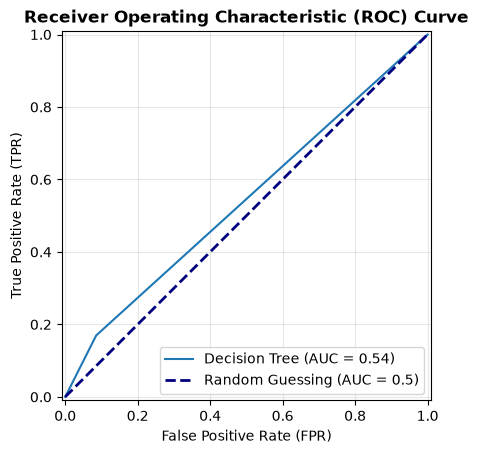

In [48]:
val_preds_proba = model_pipeline.predict_proba(X_val)[:, 1]
roc_auc = roc_auc_score(y_val, val_preds_proba)
print(f"ROC-AUC: {roc_auc:.4f}")

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_val, 
    val_preds_proba, 
    name="Decision Tree"
)

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.5)')

plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate (FPR)', fontsize=10)
plt.ylabel('True Positive Rate (TPR)', fontsize=10)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

<h3>7. Побудувати матрицю помилок (Confusion Matrix) та провести аналіз помилок (Error Analysis)</h3>

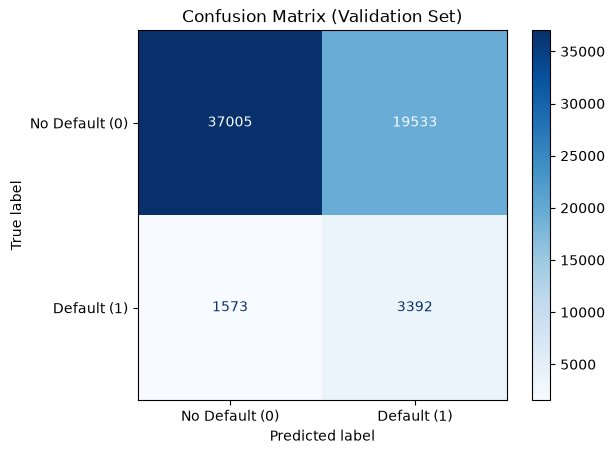

In [44]:
val_preds_class = model_pipeline.predict(X_val)
cm = confusion_matrix(y_val, val_preds_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default (0)', 'Default (1)'])
disp.plot(cmap='Blues',  values_format='d')
plt.title('Confusion Matrix (Validation Set)')
plt.show()

#### 7.1. Classification report та метрики за матрицею помилок

In [45]:
target_names = ['No Default (0)', 'Default (1)']
print(classification_report(y_val, val_preds_class, target_names=target_names, digits=3))

                precision    recall  f1-score   support

No Default (0)      0.959     0.655     0.778     56538
   Default (1)      0.148     0.683     0.243      4965

      accuracy                          0.657     61503
     macro avg      0.554     0.669     0.511     61503
  weighted avg      0.894     0.657     0.735     61503



In [46]:
test_preds_proba = model_pipeline.predict_proba(x_test_final_engineered)[:, 1]
submission = pd.DataFrame({
    'SK_ID_CURR': test_df['SK_ID_CURR'],
    'TARGET': test_preds_proba
})

submission.to_csv('submission.csv', index=False)
print("File submission.csv was saved")

File submission.csv was saved
